# Hypothesis Testing: Electronics vs Fashion
**H0:** mean order value (Electronics) = Fashion  |  **H1:** Electronics > Fashion  |  α = 0.05

In [1]:
import sys
sys.path.append('../scripts')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Image
df = pd.read_csv('../data/cleaned_sales_data.csv', parse_dates=['Order_Date'])
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales,Age_Missing,Order_ID_Reused,Month,Age_Group
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39,False,False,2025-02,26-35
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80,False,False,2025-10,56-65
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48,False,False,2025-05,56-65
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24,False,False,2025-12,56-65
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90,False,False,2025-11,36-45


In [2]:
e = df.loc[df.Category=='Electronics','Total_Sales']; f = df.loc[df.Category=='Fashion','Total_Sales']
pd.DataFrame({'n':[len(e),len(f)],'mean':[e.mean(),f.mean()],'median':[e.median(),f.median()],'std':[e.std(),f.std()]}, index=['Electronics','Fashion']).round(0)

,n,mean,median,std
Electronics,354,143442.0,114521.0,117602.0
Fashion,156,127153.0,101570.0,105150.0


## Assumption check
Equal variances? Skewed data?

In [3]:
print('Levene', stats.levene(e, f))
print('skew', e.skew().round(2), f.skew().round(2))

Levene LeveneResult(statistic=np.float64(2.8271829684478935), pvalue=np.float64(0.0932954216695191))
skew 0.99 1.21


## Primary test: Welch t-test (one-sided)

In [4]:
w = stats.ttest_ind(e, f, equal_var=False, alternative='greater'); print(w)
print('Decision:', 'Reject H0' if w.pvalue < 0.05 else 'Fail to reject H0')

TtestResult(statistic=np.float64(1.5535126183025891), pvalue=np.float64(0.060630947424000395), df=np.float64(329.0741724548586))
Decision: Fail to reject H0


## Confidence intervals

In [5]:
from confidence_interval import welch_diff_ci, bootstrap_diff_ci
print(welch_diff_ci(e, f)); print(bootstrap_diff_ci(e, f))

{'diff': np.float64(16289.14304541504), 'se': np.float64(10485.36256062922), 'dof': np.float64(329.0741724548586), 'ci_low': np.float64(-4337.652184125462), 'ci_high': np.float64(36915.93827495554), 'one_sided_lower': np.float64(-1006.4335864485365)}
{'ci_low': np.float64(-4546.410426254888), 'ci_high': np.float64(36907.87441460238), 'prob_diff_gt_0': 0.9401}


## Robustness checks

In [6]:
print('Mann-Whitney', stats.mannwhitneyu(e, f, alternative='greater'))
print('Welch on log', stats.ttest_ind(np.log(e), np.log(f), equal_var=False, alternative='greater'))
d = (e.mean()-f.mean())/np.sqrt(((len(e)-1)*e.var()+(len(f)-1)*f.var())/(len(e)+len(f)-2)); print('Cohen d', round(d,3))

Mann-Whitney MannwhitneyuResult(statistic=np.float64(29444.0), pvalue=np.float64(0.11617508551490302))
Welch on log TtestResult(statistic=np.float64(0.7987010178027849), pvalue=np.float64(0.21253457281545782), df=np.float64(313.13873569345463))
Cohen d 0.143


## Interpretation
The p-value is above 0.05 and the 95% CI for the difference includes zero, so we **fail to reject H0**: Electronics' higher average order value is not statistically significant. Its revenue lead is driven by order volume.

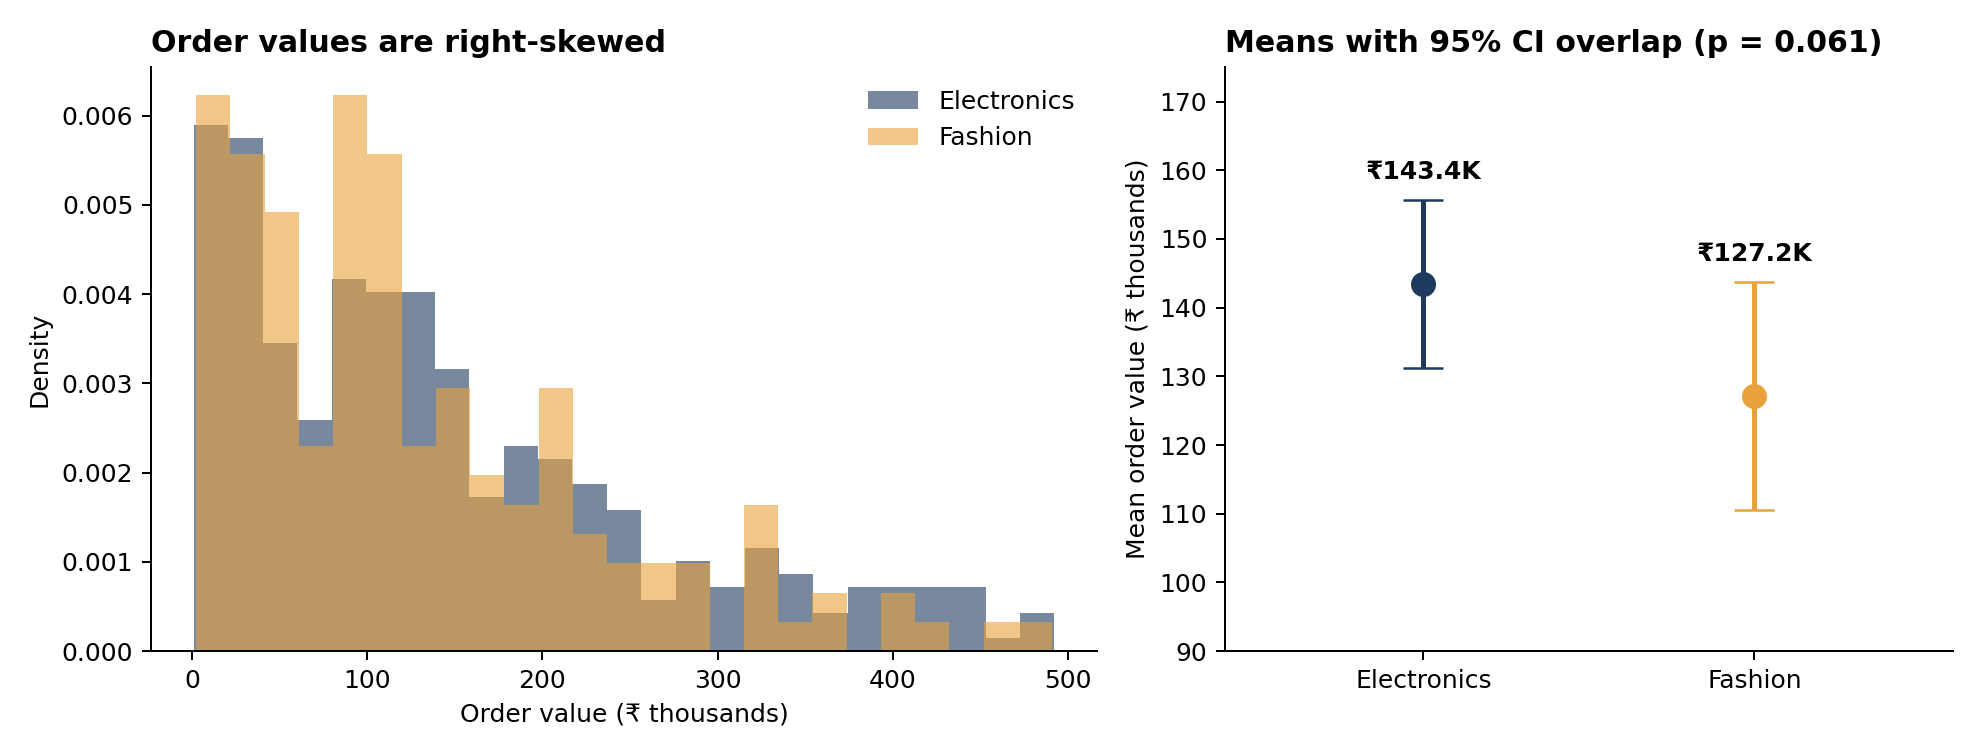

In [7]:
Image('../charts/hypothesis_test.png')